# Week 6 - Decision Trees and Random Forests
## Dataset: NOAA Storm Events

This week covers decision trees and random forests. A decision tree predicts by asking a series of yes or no questions about the features, such as "is this a thunderstorm wind event?" or "is the longitude east of -91?", and each final group (a leaf) predicts the share of training events in it that reported damage. A random forest grows hundreds of trees, each on a bootstrap sample of the training events and each allowed to consider only a random subset of features at every split, and averages their predictions.

The question is the same one Weeks 4 and 5 asked of Storm Events, whether a 2017 event had any property damage reported, with the same features and the same split that keeps whole storm episodes out of training. That makes the results directly comparable with logistic regression (Week 4) and the SVM (Week 5). It also makes this the right place to test something those weeks pointed to. Trees can carve the map into small regions, so they should be very good at picking up local differences in how damage gets reported, and very prone to memorizing individual storms.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, GroupShuffleSplit, GroupKFold, StratifiedKFold,
                                     cross_val_score)
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay)

warnings.filterwarnings('ignore', category=FutureWarning)

df = pd.read_csv('StormEvents_details-ftp_v1.0_d2017_c20260519.csv', low_memory=False)


def parse_damage(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip().upper()
    mult = {'K': 1e3, 'M': 1e6, 'B': 1e9}
    try:
        return float(val[:-1]) * mult[val[-1]] if val[-1] in mult else float(val)
    except ValueError:
        return np.nan


df['damageProperty'] = df['DAMAGE_PROPERTY'].apply(parse_damage)
print('All 2017 events:', len(df))

All 2017 events: 57041


### Data, features, and split

The features are the starting latitude and longitude, the month, the log of the event's duration, and indicators for the eight most common event types, exactly as in Weeks 4 and 5. Trees do not need the features to be scaled, because a split only cares about the order of the values, not their units, so nothing is standardized here. The split keeps every storm episode entirely in training or entirely in testing, and cross-validation inside the training set uses `GroupKFold` by episode for the same reason. Logistic regression on the same features is refit as a reference point.

In [2]:
data = df.dropna(subset=['damageProperty', 'BEGIN_LAT', 'BEGIN_LON']).copy()
data['damaged'] = (data['damageProperty'] > 0).astype(int)
begin = pd.to_datetime(data['BEGIN_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
end = pd.to_datetime(data['END_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
data['durationHours'] = ((end - begin).dt.total_seconds() / 3600).clip(lower=0)
data['logDuration'] = np.log10(data['durationHours'] + 0.1)
data['month'] = begin.dt.month
top_types = data['EVENT_TYPE'].value_counts().head(8).index
type_cols = []
for t in top_types:
    col = 'type_' + t.replace(' ', '')
    data[col] = (data['EVENT_TYPE'] == t).astype(int)
    type_cols.append(col)
data = data.dropna(subset=['month', 'logDuration']).reset_index(drop=True)
numeric = ['BEGIN_LAT', 'BEGIN_LON', 'month', 'logDuration']
features = numeric + type_cols
X = data[features]
y = data['damaged'].values
groups = data['EPISODE_ID'].values

# Same episode-grouped split as the Week 4 and Week 5 notebooks
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]
g_train = groups[train_idx]
grouped_cv = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
print('Events used:', len(data), '| share with damage reported:', round(y.mean(), 3))
print('Training events:', len(train_idx), '| test events:', len(test_idx),
      '| episodes in both:', len(set(g_train) & set(groups[test_idx])))

prep = ColumnTransformer([('num', StandardScaler(), numeric), ('types', 'passthrough', type_cols)])
logit = Pipeline([('prep', prep), ('lr', LogisticRegression(max_iter=3000))]).fit(X_train, y_train)
auc_logit = roc_auc_score(y_test, logit.predict_proba(X_test)[:, 1])
print(f'Reference, logistic regression on the same features: test ROC-AUC {auc_logit:.4f}')

Events used: 31863 | share with damage reported: 0.347
Training events: 23902 | test events: 7961 | episodes in both: 0
Reference, logistic regression on the same features: test ROC-AUC 0.8212


### A shallow tree first

A tree limited to three levels of questions is small enough to read, so it shows what the data looks like to a tree before any tuning.

Depth-3 tree, test ROC-AUC on unseen episodes: 0.7895

|--- type_ThunderstormWind <= 0.50
|   |--- type_Tornado <= 0.50
|   |   |--- logDuration <= -0.68
|   |   |   |--- class: 0
|   |   |--- logDuration >  -0.68
|   |   |   |--- class: 0
|   |--- type_Tornado >  0.50
|   |   |--- BEGIN_LON <= -98.37
|   |   |   |--- class: 0
|   |   |--- BEGIN_LON >  -98.37
|   |   |   |--- class: 1
|--- type_ThunderstormWind >  0.50
|   |--- BEGIN_LON <= -91.35
|   |   |--- month <= 4.50
|   |   |   |--- class: 0
|   |   |--- month >  4.50
|   |   |   |--- class: 0
|   |--- BEGIN_LON >  -91.35
|   |   |--- BEGIN_LAT <= 31.06
|   |   |   |--- class: 0
|   |   |--- BEGIN_LAT >  31.06
|   |   |   |--- class: 1



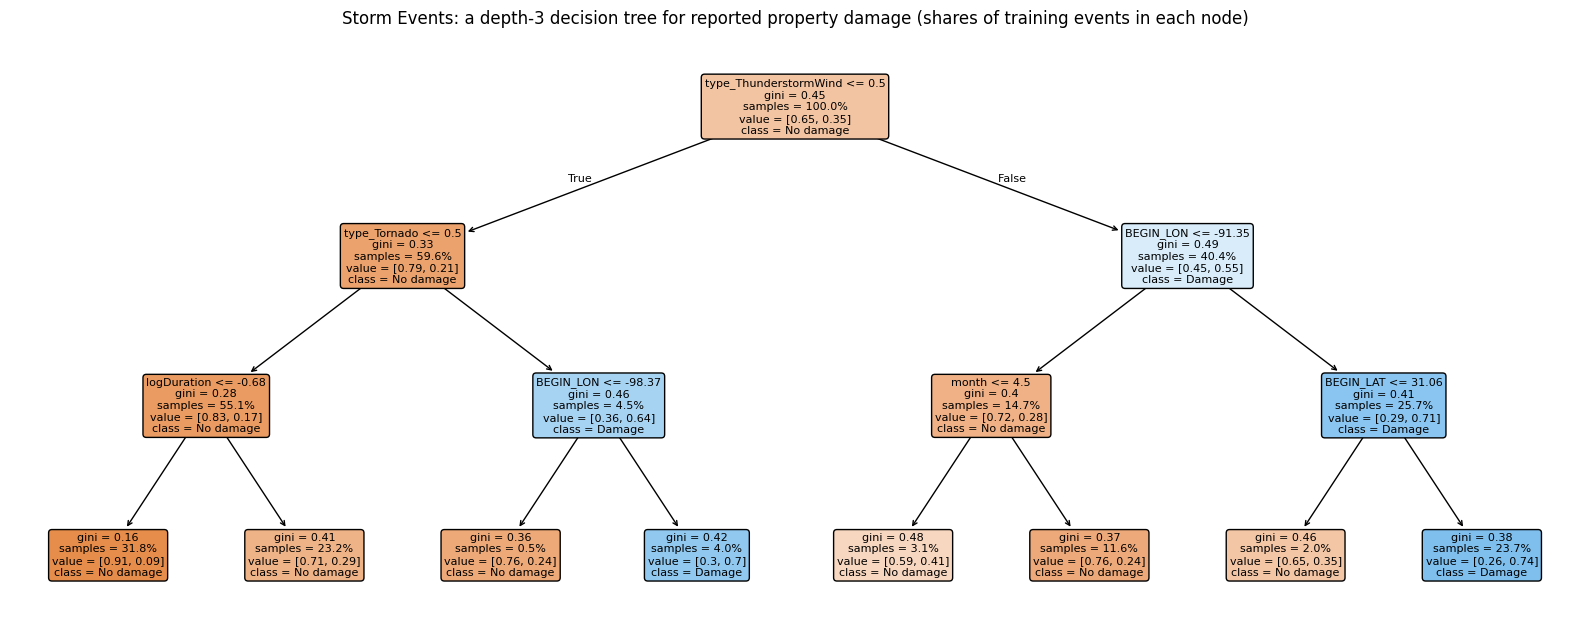

In [3]:
shallow = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
print(f'Depth-3 tree, test ROC-AUC on unseen episodes: {roc_auc_score(y_test, shallow.predict_proba(X_test)[:, 1]):.4f}')
print()
print(export_text(shallow, feature_names=features, decimals=2))

fig, ax = plt.subplots(figsize=(16, 6.5))
plot_tree(shallow, feature_names=features, class_names=['No damage', 'Damage'], filled=True, rounded=True,
          proportion=True, precision=2, fontsize=8, ax=ax)
ax.set_title('Storm Events: a depth-3 decision tree for reported property damage (shares of training events in each node)')
plt.tight_layout()
plt.show()

The first question the tree asks is whether the event is a thunderstorm wind, and most of the questions after that are about longitude. Thunderstorm wind events east of about -91.35 degrees (roughly the Mississippi River) and north of 31 degrees latitude make up 23.7% of training events, and 74% of them reported damage. West of that line, only 28% of thunderstorm wind events did. Tornadoes east of -98.4 degrees reported damage 70% of the time. Even this small tree reaches a test ROC-AUC of 0.790 on unseen episodes.

Geography shows up immediately, and it is unlikely that thunderstorm winds are physically less damaging west of the Mississippi. Week 4 found that the National Weather Service office writing up an event changes the odds of a damage report by a huge amount, and offices cover fixed regions. A tree can approximate those regions with a few cuts on latitude and longitude.

### How deep should a tree grow?

A tree with no depth limit keeps splitting until every leaf is pure, so it can memorize the training data completely. The next cell grows trees from depth 1 to 25 and scores them three ways, on the training data, with random 5-fold cross-validation, and with 5-fold cross-validation grouped by storm episode.

Took 46 seconds
 max_depth  Train AUC  Random CV AUC  Grouped CV AUC
         1     0.6851         0.6851          0.6855
         2     0.7582         0.7581          0.7584
         3     0.8031         0.7861          0.7803
         4     0.8360         0.8272          0.8236
         5     0.8535         0.8449          0.8311
         6     0.8728         0.8627          0.8361
         8     0.9066         0.8816          0.8498
         9     0.9271         0.8880          0.8567
        10     0.9430         0.8903          0.8519
        12     0.9695         0.8845          0.8386
        15     0.9902         0.8616          0.8100
        20     0.9992         0.8424          0.7946
        25     1.0000         0.8371          0.7870
Best depth by grouped CV: 9 | best depth by random CV: 11


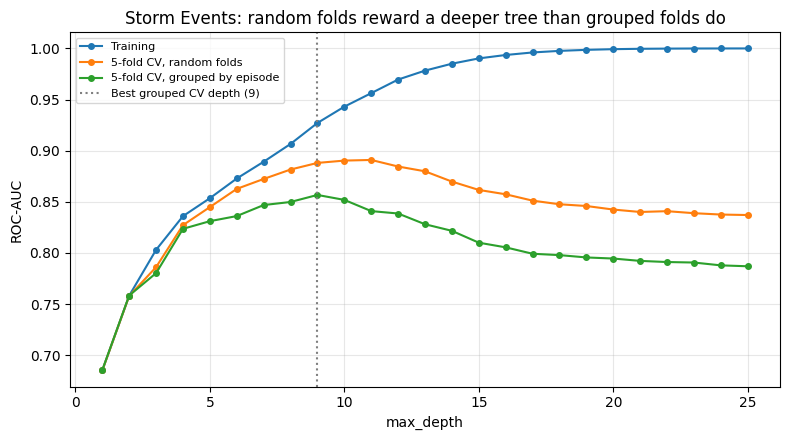

In [4]:
depths = list(range(1, 26))
t0 = time.time()
rows = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=0)
    s_group = cross_val_score(tree, X_train, y_train, cv=grouped_cv, scoring='roc_auc', n_jobs=-1)
    s_random = cross_val_score(tree, X_train, y_train, cv=random_cv, scoring='roc_auc', n_jobs=-1)
    fit = tree.fit(X_train, y_train)
    rows.append({'max_depth': d, 'Train AUC': roc_auc_score(y_train, fit.predict_proba(X_train)[:, 1]),
                 'Random CV AUC': s_random.mean(), 'Grouped CV AUC': s_group.mean()})
depth_curve = pd.DataFrame(rows)
best_depth = int(depth_curve.loc[depth_curve['Grouped CV AUC'].idxmax(), 'max_depth'])
best_depth_random = int(depth_curve.loc[depth_curve['Random CV AUC'].idxmax(), 'max_depth'])
print(f'Took {time.time() - t0:.0f} seconds')
print(depth_curve[depth_curve['max_depth'].isin([1, 2, 3, 4, 5, 6, 8, 9, 10, 12, 15, 20, 25])].round(4).to_string(index=False))
print(f'Best depth by grouped CV: {best_depth} | best depth by random CV: {best_depth_random}')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(depths, depth_curve['Train AUC'], marker='o', markersize=4, label='Training')
ax.plot(depths, depth_curve['Random CV AUC'], marker='o', markersize=4, label='5-fold CV, random folds')
ax.plot(depths, depth_curve['Grouped CV AUC'], marker='o', markersize=4, label='5-fold CV, grouped by episode')
ax.axvline(best_depth, color='gray', linestyle=':', label=f'Best grouped CV depth ({best_depth})')
ax.set_xlabel('max_depth')
ax.set_ylabel('ROC-AUC')
ax.set_title('Storm Events: random folds reward a deeper tree than grouped folds do')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Training ROC-AUC climbs steadily to 1.000 at depth 25, which is pure memorization. The two cross-validation curves tell different stories. With random folds, the best depth is 11 (CV ROC-AUC about 0.89), because events from the same storm sit in both the training and validation folds and a deep tree can recognize them. With folds grouped by episode, the best depth is 9 (0.857), and by depth 25 the grouped score falls to 0.787 while the random score is still 0.837. The gap between the two curves grows with depth, from about 0.006 at depth 3 to about 0.05 at depth 25, because deeper trees memorize more of each storm.

### Random forests, and whether the out-of-bag score can be trusted

A single deep tree has high variance, since a small change in the training data can change its splits completely. A random forest reduces that variance by averaging many trees grown on bootstrap samples, with `max_features` limiting how many features each split may consider so the trees do not all look alike. The main settings are `max_features` (3, 6, or all 12, where 12 is plain bagging) and `min_samples_leaf`, the smallest number of training events allowed in a leaf, which controls how fine the trees can cut.

Random forests come with a built-in validation score. Each tree leaves out about a third of the training events from its bootstrap sample, and the out-of-bag (OOB) score predicts each event using only the trees that did not see it. The catch is that the trees that did not see an event still saw the other events from the same storm, so the OOB score should be optimistic for clustered data. The next cell tunes the forest with both the OOB score and grouped cross-validation, and also scores every setting on the test episodes.

Grid of 18 forests took 257 seconds
 min_samples_leaf  max_features  OOB AUC  Grouped CV AUC  Test AUC (unseen episodes)
                1             3   0.9444          0.9083                      0.9066
                1             6   0.9460          0.9118                      0.9116
                1            12   0.9436          0.9086                      0.9085
                3             3   0.9469          0.9114                      0.9119
                3             6   0.9487          0.9148                      0.9163
                3            12   0.9468          0.9122                      0.9131
               10             3   0.9387          0.9062                      0.9080
               10             6   0.9430          0.9119                      0.9160
               10            12   0.9433          0.9120                      0.9151
               30             3   0.9220          0.8945                      0.8959
               30            

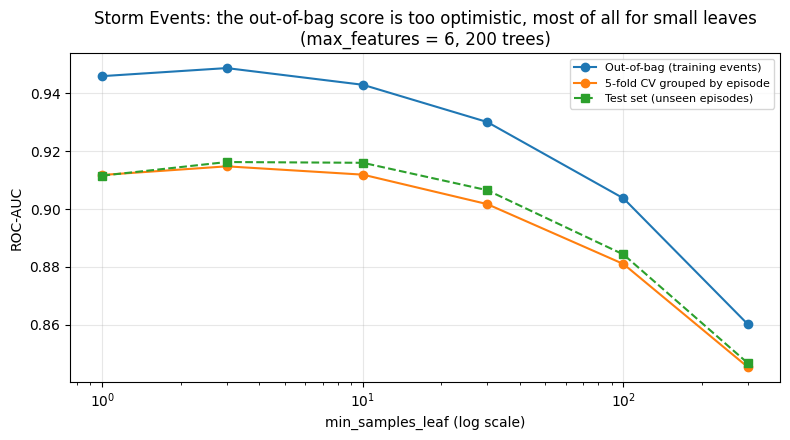

In [5]:
t0 = time.time()
rows = []
for leaf in [1, 3, 10, 30, 100, 300]:
    for mf in [3, 6, 12]:
        rf = RandomForestClassifier(n_estimators=200, max_features=mf, min_samples_leaf=leaf, oob_score=True,
                                    n_jobs=-1, random_state=0)
        s_group = cross_val_score(rf, X_train, y_train, cv=grouped_cv, scoring='roc_auc')
        rf.fit(X_train, y_train)
        rows.append({'min_samples_leaf': leaf, 'max_features': mf,
                     'OOB AUC': roc_auc_score(y_train, rf.oob_decision_function_[:, 1]),
                     'Grouped CV AUC': s_group.mean(),
                     'Test AUC (unseen episodes)': roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])})
rf_grid = pd.DataFrame(rows)
print(f'Grid of {len(rf_grid)} forests took {time.time() - t0:.0f} seconds')
print(rf_grid.round(4).to_string(index=False))
by_oob = rf_grid.loc[rf_grid['OOB AUC'].idxmax()]
by_group = rf_grid.loc[rf_grid['Grouped CV AUC'].idxmax()]
print()
print(f"Chosen by OOB AUC: min_samples_leaf = {int(by_oob['min_samples_leaf'])}, max_features = {int(by_oob['max_features'])} "
      f"(OOB {by_oob['OOB AUC']:.4f}, test {by_oob['Test AUC (unseen episodes)']:.4f})")
print(f"Chosen by grouped CV: min_samples_leaf = {int(by_group['min_samples_leaf'])}, max_features = {int(by_group['max_features'])} "
      f"(grouped CV {by_group['Grouped CV AUC']:.4f}, test {by_group['Test AUC (unseen episodes)']:.4f})")

fig, ax = plt.subplots(figsize=(8, 4.5))
part = rf_grid[rf_grid['max_features'] == int(by_group['max_features'])]
ax.semilogx(part['min_samples_leaf'], part['OOB AUC'], marker='o', label='Out-of-bag (training events)')
ax.semilogx(part['min_samples_leaf'], part['Grouped CV AUC'], marker='o', label='5-fold CV grouped by episode')
ax.semilogx(part['min_samples_leaf'], part['Test AUC (unseen episodes)'], marker='s', linestyle='--',
            label='Test set (unseen episodes)')
ax.set_xlabel('min_samples_leaf (log scale)')
ax.set_ylabel('ROC-AUC')
ax.set_title(f"Storm Events: the out-of-bag score is too optimistic, most of all for small leaves\n(max_features = {int(by_group['max_features'])}, 200 trees)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The OOB score is optimistic at every setting, by 0.012 to 0.036, and the gap is largest when leaves are small and the trees can memorize the most. For the chosen setting, the OOB ROC-AUC is 0.949 while grouped cross-validation gives 0.915 and the test episodes give 0.916. Grouped CV matches the test set closely, and the OOB score does not.

In this case both methods pick the same setting, `min_samples_leaf = 3` and `max_features = 6`, so the optimism did not change the model. It would have changed the reported score, though. Anyone reading the OOB number would expect 0.949 on new storms and get 0.916. Large leaves hurt for a different reason. With 300 events per leaf the forest cannot follow the local patterns that matter here, and the test score drops to between 0.84 and 0.85.

### Which features does the forest rely on?

Random forests report impurity-based importance (how much each feature reduced impurity across all splits, measured on the training data). Permutation importance instead shuffles one feature at a time on the test set and measures how much ROC-AUC drops. The two can disagree, because impurity-based importance favors features with many distinct values.

                             Impurity-based (MDI)  Permutation (drop in test AUC)
type_ThunderstormWind                      0.1196                          0.1864
BEGIN_LON                                  0.3257                          0.1648
BEGIN_LAT                                  0.2390                          0.1022
logDuration                                0.1169                          0.0633
type_Tornado                               0.0343                          0.0203
type_Hail                                  0.0509                          0.0132
type_Lightning                             0.0243                          0.0101
month                                      0.0553                          0.0077
type_FlashFlood                            0.0100                          0.0066
type_MarineThunderstormWind                0.0134                          0.0028
type_HeavyRain                             0.0063                          0.0024
type_Flood      

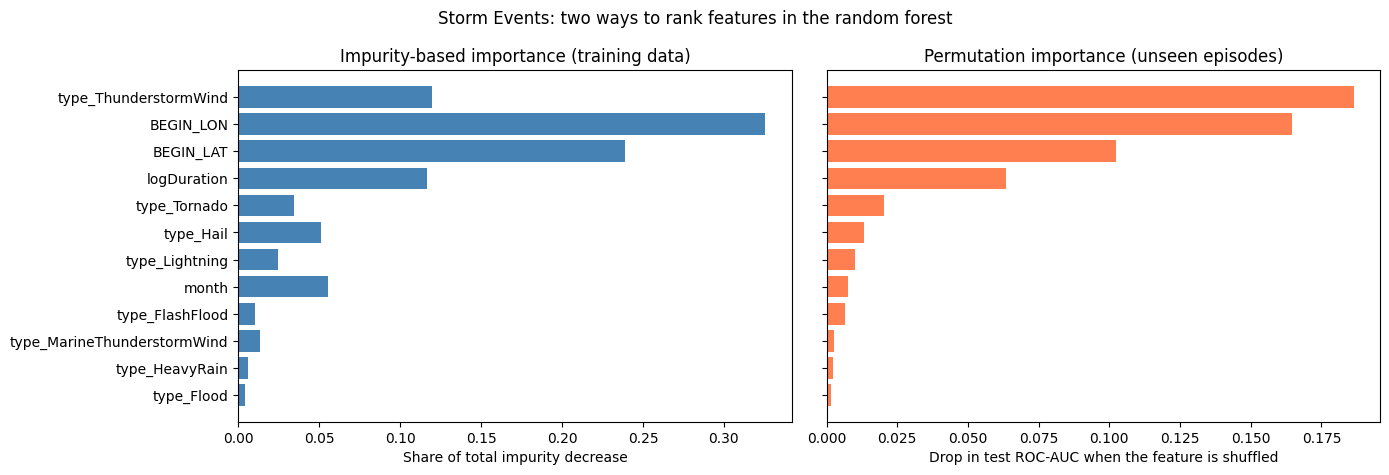

In [6]:
final_rf = RandomForestClassifier(n_estimators=400, max_features=int(by_group['max_features']),
                                  min_samples_leaf=int(by_group['min_samples_leaf']), n_jobs=-1,
                                  random_state=0).fit(X_train, y_train)
perm = permutation_importance(final_rf, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=0, n_jobs=-1)
imp = pd.DataFrame({'Impurity-based (MDI)': final_rf.feature_importances_,
                    'Permutation (drop in test AUC)': perm.importances_mean}, index=features)
imp = imp.sort_values('Permutation (drop in test AUC)')
print(imp.iloc[::-1].round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
axes[0].barh(imp.index, imp['Impurity-based (MDI)'], color='steelblue')
axes[0].set_xlabel('Share of total impurity decrease')
axes[0].set_title('Impurity-based importance (training data)')
axes[1].barh(imp.index, imp['Permutation (drop in test AUC)'], color='coral')
axes[1].set_xlabel('Drop in test ROC-AUC when the feature is shuffled')
axes[1].set_title('Permutation importance (unseen episodes)')
fig.suptitle('Storm Events: two ways to rank features in the random forest')
plt.tight_layout()
plt.show()

The two importance measures agree on the top four features but not their order. Impurity-based importance puts longitude (0.33) and latitude (0.24) far ahead of everything else, while permutation importance ranks the thunderstorm wind indicator first (a 0.186 drop in test ROC-AUC when shuffled), then longitude (0.165), latitude (0.102), and log duration (0.063). Latitude and longitude have thousands of distinct values, so they get many chances to split and collect impurity credit, which is the bias permutation importance avoids. Either way, location is doing a large share of the work.

### Final evaluation on held-out storm episodes

Test events (unseen episodes): 7961
                              Model  Accuracy  Balanced acc.     F1  ROC-AUC
                     Majority class    0.6514         0.5000 0.0000   0.5000
Logistic regression (same features)    0.7715         0.7438 0.6656   0.8212
       Decision tree, max_depth = 9    0.8289         0.7890 0.7281   0.8610
   Random forest tuned by OOB score    0.8501         0.8208 0.7711   0.9165
  Random forest tuned by grouped CV    0.8501         0.8208 0.7711   0.9165

From earlier notebooks on this split: logistic regression (Week 4) 0.821, tuned RBF SVM (Week 5) 0.841



                             Model  Random split AUC  Episode split AUC    Gap
               Logistic regression            0.8268             0.8212 0.0055
Random forest, tuned by grouped CV            0.9449             0.9165 0.0285
       Random forest, tuned by OOB            0.9449             0.9165 0.0285


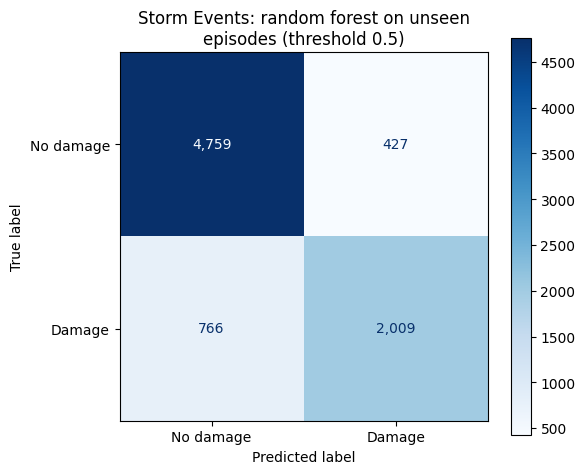

In [7]:
def scores(name, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {'Model': name, 'Accuracy': accuracy_score(y_test, pred),
            'Balanced acc.': balanced_accuracy_score(y_test, pred), 'F1': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, prob)}


depth_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=0).fit(X_train, y_train)
oob_rf = RandomForestClassifier(n_estimators=400, max_features=int(by_oob['max_features']),
                                min_samples_leaf=int(by_oob['min_samples_leaf']), n_jobs=-1,
                                random_state=0).fit(X_train, y_train)
p_rf = final_rf.predict_proba(X_test)[:, 1]
results = pd.DataFrame([
    scores('Majority class', np.full(len(y_test), y_train.mean())),
    scores('Logistic regression (same features)', logit.predict_proba(X_test)[:, 1]),
    scores(f'Decision tree, max_depth = {best_depth}', depth_tree.predict_proba(X_test)[:, 1]),
    scores('Random forest tuned by OOB score', oob_rf.predict_proba(X_test)[:, 1]),
    scores('Random forest tuned by grouped CV', p_rf),
])
print('Test events (unseen episodes):', len(y_test))
print(results.round(4).to_string(index=False))
print()
print('From earlier notebooks on this split: logistic regression (Week 4) 0.821, tuned RBF SVM (Week 5) 0.841')

r_train, r_test = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=0)
rows = []
for name, model in [('Logistic regression', Pipeline([('prep', prep), ('lr', LogisticRegression(max_iter=3000))])),
                    ('Random forest, tuned by grouped CV', RandomForestClassifier(
                        n_estimators=400, max_features=int(by_group['max_features']),
                        min_samples_leaf=int(by_group['min_samples_leaf']), n_jobs=-1, random_state=0)),
                    ('Random forest, tuned by OOB', RandomForestClassifier(
                        n_estimators=400, max_features=int(by_oob['max_features']),
                        min_samples_leaf=int(by_oob['min_samples_leaf']), n_jobs=-1, random_state=0))]:
    model.fit(X.iloc[r_train], y[r_train])
    random_auc = roc_auc_score(y[r_test], model.predict_proba(X.iloc[r_test])[:, 1])
    model.fit(X_train, y_train)
    rows.append({'Model': name, 'Random split AUC': random_auc,
                 'Episode split AUC': roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])})
print()
print(pd.DataFrame(rows).assign(Gap=lambda t: t['Random split AUC'] - t['Episode split AUC']).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, (p_rf >= 0.5).astype(int), display_labels=['No damage', 'Damage'],
                                        cmap='Blues', values_format=',', ax=ax)
ax.set_title('Storm Events: random forest on unseen\nepisodes (threshold 0.5)')
plt.tight_layout()
plt.show()

On the 7,961 test events from unseen episodes, the random forest reaches a ROC-AUC of 0.917, an accuracy of 0.850, a balanced accuracy of 0.821, and an F1 of 0.771. A single tree of depth 9 reaches 0.861 and logistic regression on the same features 0.821. For comparison, the tuned RBF SVM in Week 5 reached 0.841 on this same split. The forest's advantage holds on unseen storms, and its gap between a random split and the episode split (0.945 against 0.917, a gap of 0.029) is about five times the gap for logistic regression (0.006), which confirms that the forest leans on storm-specific patterns more than the linear model does.

## Discussion

### Overfitting

Trees are the most overfitting-prone model in this course so far, and this notebook used three defenses. Limiting depth was the first. Grouped cross-validation chose depth 9, where an unlimited tree would score 1.000 on training data and about 0.79 on new storms. Averaging was the second. A random forest of 400 trees with `min_samples_leaf = 3` beats the best single tree by 0.056 in test ROC-AUC, because averaging cancels out much of each tree's variance. Grouped validation was the third and most important, since both random folds and the OOB score reward a forest for recognizing storms it has already seen.

The OOB result is worth stating plainly. It overstated the forest's skill by about 0.03, and the overstatement grew as the leaves got smaller. It did not lead to a worse model here, because the best setting was the same under both methods, but on clustered data the OOB score should not be reported as an estimate of performance on new events.

### Metrics and hyperparameter tuning

ROC-AUC was the main metric because only about 35% of events report damage and ROC-AUC does not depend on a single cutoff. Always predicting no damage already gives 0.651 accuracy and an F1 of zero, so accuracy alone would mislead. The tuned settings were `max_depth` for the single tree (9), and `min_samples_leaf` (3) and `max_features` (6 of 12) for the forest. A smaller `min_samples_leaf` lets the trees cut the map more finely, and a smaller `max_features` makes the trees more different from each other, which helps the average. The number of trees was fixed at 400 for the final model, since more trees only reduce variance and do not cause overfitting.

### Expected or unexpected

I expected trees to beat logistic regression, since damage reporting clearly depends on combinations like event type and region. I did not expect the margin to be this large. The forest's 0.917 is close to the 0.909 that Week 4's logistic regression reached only after adding about 100 indicators for the reporting office, and it gets there using coordinates alone. That points to the same explanation as Week 4. Much of what predicts whether damage gets reported is which office covers the area, and a forest can learn those regions from latitude and longitude. So the high score is real on unseen storms, but it describes reporting practice more than storm severity.

I also expected the OOB score to choose a more overfit forest than grouped CV did. It did not, which was a useful reminder to check that kind of expectation instead of assuming it.

### How EDA helped

The Week 4 and Week 5 finding that events cluster by episode (5,220 episodes for 31,863 events) is why every score in this notebook uses grouped validation, and it is what made the OOB comparison worth running. The office reporting differences found in Weeks 4 and 5 explained why the shallow tree splits on longitude so early and why location dominates the importances. The Module B finding that damage is extremely right-skewed is why the target is whether damage was reported, not the amount.

### External sources

- scikit-learn User Guide, "Decision Trees," including minimal cost-complexity pruning: https://scikit-learn.org/stable/modules/tree.html
- scikit-learn User Guide, "Ensembles," the section on random forests and out-of-bag estimates: https://scikit-learn.org/stable/modules/ensemble.html#forest
- scikit-learn example, "Permutation Importance vs Random Forest Feature Importance (MDI)": https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance.html
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.

### Conclusions

A random forest predicts whether a 2017 storm event reported property damage with a test ROC-AUC of 0.917 on storms it never saw, the best result for this question across Weeks 4 through 6 (logistic regression 0.821, SVM 0.841, single tree 0.861). The improvement is real under grouped validation, but most of it comes from location, which the forest uses to learn regional differences in how damage is reported.

For the Capstone, this sharpens the main caution about Storm Events. A model of the damage field will always partly model the people filling it in. Any model meant to explain storm damage from storm conditions should be evaluated with grouped validation and should treat high-resolution location carefully, because location can stand in for reporting practice. The OOB result adds one more rule, that a built-in validation score is only as good as its assumption that the rows are independent.